# Homework #3
## Introduction to deep learning


This colaboratory contains Homework #3 which is due **October 22 midnight (23:59 EET time)**. To complete the homework, extract **(File -> Download .ipynb)** and submit to the course webpage.

**NB! Links to your colaboratory will not be accepted as a solution!**
## Submission's rules:

1.   Please, submit only .ipynb that you extract from the Colaboratory.
2. Run your homework exercises before submitting (output should be present, preferably restart the kernel and press run all the cells).
3. Do not change the description of tasks in red (even if there is a typo|mistake|etc).
4. Please, make sure to avoid unnecessary long printouts.
5. Each task should be solved right under the question of the task and not elsewhere.
6. Solutions to both regular and bonus exercises should be submitted in one IPYNB file.


##List of Homework's exercises:

1.   [Ex1](#scrollTo=4YtaQwccjrAL) - 4 points
2.   [Ex2](#scrollTo=tOfgGIUtIizt) - 4 points
3.   [Ex3](#scrollTo=rt6Fuo28nQkd) - 2 points
4.   [Bonus 1](#scrollTo=wT-4aQqUtDU7) - 2 points
5.   [Bonus 2](#scrollTo=lEW4oyQhnRQA) - 2 points


In [41]:
# A bit of setup
import numpy as np
import matplotlib.pyplot as plt

Here we will define few functions that will help us visualise classifiers that we are going to build in this class. Don't worry if you don't understand this code completely.

In [73]:
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading extenrnal modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

# for very shallow models
def plot_classifier(X, y, W, b):
  st = 0.02
  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, st),
                       np.arange(y_min, y_max, st))
  Z = np.dot(np.c_[xx.ravel(), yy.ravel()], W) + b
  Z = np.argmax(Z, axis=1)
  Z = Z.reshape(xx.shape)
  fig = plt.figure()
  plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

# for two-layer network
def plot_neural_network(X, y, W,b ,W2, b2):
  st = 0.02
  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, st),
                       np.arange(y_min, y_max, st))
  Z = np.dot(np.maximum(0, np.dot(np.c_[xx.ravel(), yy.ravel()], W) + b), W2) + b2
  Z = np.argmax(Z, axis=1)
  Z = Z.reshape(xx.shape)

  fig = plt.figure()
  plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [43]:
N = 100 # number of points per class
D = 2 # number of features (dimensions)
K = 2 # number of classes (purple and red circles)
X = np.zeros((N*K,D)) # data matrix (each row = single example)
num_examples = X.shape[0]
y = np.zeros((N*K, 1), dtype='int') # class labels

In [44]:
# Creating spiral data points
np.random.seed(1111)

for j in range(K):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
  y[ix, 0] = j

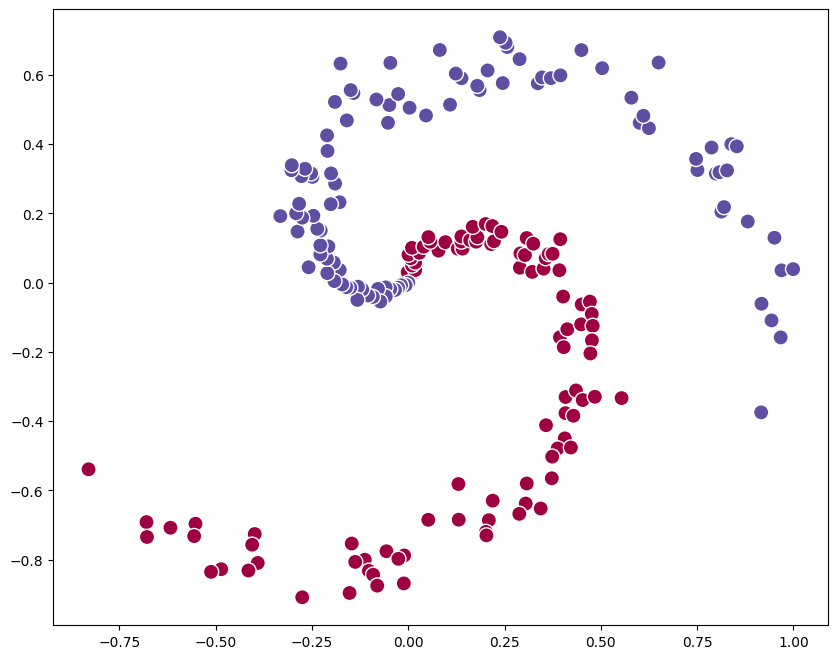

In [45]:
# this is matplotlib...
plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
plt.show()

For our implementation we would need to transform the vector of correct labels `y` into one hot encoded matrix, let's call it `truth`. Сreating `truth` as one-hot encoded labels (`y`)

In [46]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(handle_unknown='ignore')
truth = enc.fit_transform(y).toarray()

# first column is for red
# second is for purple class

## Homework exercise 1 (4 points): three-layer network
 <font color='red'>In the class we have obtained ~94% using 2-layer neural network when classifying points in spiral. This is surely not good enough for us. Hence, let's make a few tweaks in attempt to reach higher performance.</font>

<font color='red'>**PS: Before you start working on this task, please read it in its entirety!**</font>

<font color='red'> **(a)** Based on the code we have written in the practice session, build a new 3-layer neural network, consiting two hidden layers (each of size `h`) and one output layer. Use `tanh` as an activation function for the hidden layers. Compute both feedforward and backpropagation paths to update the model weights and produce predictions. Answer a question at the end of this subtask. **(1.5 points)**. </font>

In [47]:
num_examples = X.shape[0]

# Initialize parameters randomly
h = 100  # Size of hidden layer
W = np.random.randn(D,h)
b = np.zeros((1,h))
W2 = np.random.randn(h,h)
b2 = np.zeros((1,h))
W3 = np.random.randn(h,K)
b3 = np.zeros((1,K))

# Some hyperparameters
step_size = 1e-0

# Gradient descent loop
##### YOUR CODE STARTS #####
for i in range(2000):

  # Forward path
  # print(W.shape)
  # print(X.shape)
  hidden_layer = np.tanh(X @ W + b)
  # print(hidden_layer.shape)
  hidden_layer_2 = np.tanh(hidden_layer @ W2 + b2)
  answers = hidden_layer_2 @ W3 + b3
  # print(answers.shape)

  # Compute the error: average sum of squared differences
  total_error = 0.5 * np.sum((answers - truth)**2)
  total_error = total_error / num_examples # to complete the MSE

  if i % 100 == 0:
    print("iteration %d: loss %e" % (i, total_error))

  # Compute the gradient on answers
  dTEdA = answers - truth
  dTEdA /= num_examples

  # Backpropagate the gradient to the parameters
  # First backprop into parameters W3 and b3
  dW3 = hidden_layer_2.T @ dTEdA
  db3 = np.sum(dTEdA, axis = 0, keepdims=True)

  # Backprop into hidden layer 2
  dH2 = dTEdA @ W3.T

  # Then backprop into W2 and b2
  dW2 = hidden_layer.T @ ((1 - hidden_layer_2 ** 2) * dH2)
  db2 = np.sum(dH2 * (1 - hidden_layer_2 ** 2), axis = 0, keepdims=True)

  # Backprop into hidden layer
  dH = dH2 @ W2.T

  # Finally into W,b
  dW = X.T @ ((1 - hidden_layer ** 2) * dH)
  db = np.sum(dH * (1 - hidden_layer ** 2), axis=0, keepdims=True)

  # Perform a parameter update
  W += -step_size * dW
  b += -step_size * db
  W2 += -step_size * dW2
  b2 += -step_size * db2
  W3 += -step_size * dW3
  b3 += -step_size * db3
  ##### YOUR CODE ENDS #####

iteration 0: loss 8.335985e+01
iteration 100: loss nan
iteration 200: loss nan
iteration 300: loss nan
iteration 400: loss nan
iteration 500: loss nan
iteration 600: loss nan
iteration 700: loss nan
iteration 800: loss nan
iteration 900: loss nan
iteration 1000: loss nan
iteration 1100: loss nan
iteration 1200: loss nan
iteration 1300: loss nan
iteration 1400: loss nan
iteration 1500: loss nan
iteration 1600: loss nan
iteration 1700: loss nan
iteration 1800: loss nan
iteration 1900: loss nan


<font color='red'> If you have implemented everything correctly, you should have encountered a problem :)
Below name the problem and describe why it happens: </font>

<font color='red'> Your answer: </font>
Hyper parameter `step_size` had a large value. During running feed forward and backpropogate the learning rate was too high so we missed the optimum. I think the simplest strategy is to reduce the learning rage (reduce the `step_size`).

<font color='red'> **(b)** Fix the issue you have encountered above using one of the ideas that we have discussed in the lecture. Please, insert and run the updated code in the cell below. **(1.5 points)**. </font>

In [65]:
##### YOUR CODE STARTS #####
num_examples = X.shape[0]

# Initialize parameters randomly
h = 100  # Size of hidden layer
W = np.random.randn(D,h)
b = np.zeros((1,h))
W2 = np.random.randn(h,h)
b2 = np.zeros((1,h))
W3 = np.random.randn(h,K)
b3 = np.zeros((1,K))

# Some hyperparameters
step_size = 1e-2

# Gradient descent loop
##### YOUR CODE STARTS #####
for i in range(2000):

  # Forward path
  # print(W.shape)
  # print(X.shape)
  hidden_layer = np.tanh(X @ W + b)
  # print(hidden_layer.shape)
  hidden_layer_2 = np.tanh(hidden_layer @ W2 + b2)
  answers = hidden_layer_2 @ W3 + b3
  # print(answers.shape)

  # Compute the error: average sum of squared differences
  total_error = 0.5 * np.sum((answers - truth)**2)
  total_error = total_error / num_examples # to complete the MSE

  if i % 100 == 0:
    print("iteration %d: loss %e" % (i, total_error))

  # Compute the gradient on answers
  dTEdA = answers - truth
  dTEdA /= num_examples

  # Backpropagate the gradient to the parameters
  # First backprop into parameters W3 and b3
  dW3 = hidden_layer_2.T @ dTEdA
  db3 = np.sum(dTEdA, axis = 0, keepdims=True)

  # Backprop into hidden layer 2
  dH2 = dTEdA @ W3.T

  # Then backprop into W2 and b2
  dW2 = hidden_layer.T @ ((1 - hidden_layer_2 ** 2) * dH2)
  db2 = np.sum(dH2 * (1 - hidden_layer_2 ** 2), axis = 0, keepdims=True)

  # Backprop into hidden layer
  dH = dH2 @ W2.T

  # Finally into W,b
  dW = X.T @ ((1 - hidden_layer ** 2) * dH)
  db = np.sum(dH * (1 - hidden_layer ** 2), axis=0, keepdims=True)

  # Perform a parameter update
  W += -step_size * dW
  b += -step_size * db
  W2 += -step_size * dW2
  b2 += -step_size * db2
  W3 += -step_size * dW3
  b3 += -step_size * db3
##### YOUR CODE ENDS #####

iteration 0: loss 9.743016e+01
iteration 100: loss 2.608089e-01
iteration 200: loss 1.792571e-01
iteration 300: loss 1.220997e-01
iteration 400: loss 9.457909e-02
iteration 500: loss 8.628850e-02
iteration 600: loss 8.288691e-02
iteration 700: loss 8.010694e-02
iteration 800: loss 7.694820e-02
iteration 900: loss 7.336381e-02
iteration 1000: loss 6.940376e-02
iteration 1100: loss 6.506388e-02
iteration 1200: loss 6.047447e-02
iteration 1300: loss 5.613772e-02
iteration 1400: loss 5.206401e-02
iteration 1500: loss 4.794806e-02
iteration 1600: loss 4.408265e-02
iteration 1700: loss 4.073635e-02
iteration 1800: loss 3.787005e-02
iteration 1900: loss 3.533144e-02


<font color='red'> If it worked fine, evaluate your model running the code below. </font>

In [66]:
#evaluate training set accuracy
hidden_layer = np.tanh(np.dot(X, W) + b)
hidden_layer_2 = np.tanh(np.dot(hidden_layer, W2) + b2) # NB, tanh activation
answers = np.dot(hidden_layer_2, W3) + b3 # Note, no activation function for the last layer!
predicted_class = np.argmax(answers, axis=1)
print('training accuracy: %.2f' % (np.mean(predicted_class == y[:,0])))

training accuracy: 0.98


<font color='red'> You should get about 98% of accuracy or more... </font>



<font color='red'> **(c)** Update function `plot_deep_neural_network` by altering the code of `plot_neural_network` to visualise obtained 3-layer network with `tanh` activation function. Visualise obtained decision boundary. How did it change comparing to the one we have observed by 2-layer models? Do you think you would be able to easily get 100% for this data? **(1 point)** </font>



In [70]:
def plot_deep_neural_network(X, y, W, b ,W2, b2, W3, b3):
  h = 0.02
  x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
  y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                       np.arange(y_min, y_max, h))

  ##### YOUR CODE STARTS #####

  hidden_layer = np.tanh(np.dot(np.c_[xx.ravel(), yy.ravel()], W) + b)
  hidden_layer_2 = np.tanh(hidden_layer @ W2 + b2)
  Z = hidden_layer_2 @ W3 + b3

  ##### YOUR CODE ENDS #####

  Z = np.argmax(Z, axis=1)
  Z = Z.reshape(xx.shape)
  fig = plt.figure()
  plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
  plt.scatter(X[:, 0], X[:, 1], c=y, s=120, edgecolors = 'white', cmap=plt.cm.Spectral)
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())

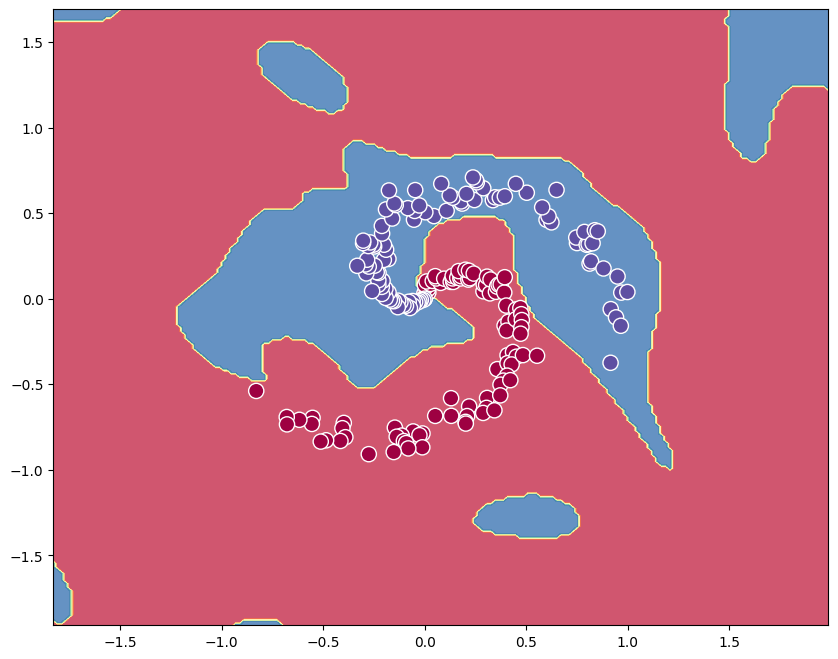

In [75]:
# plot the resulting classifier
plot_deep_neural_network(X, y, W, b, W2, b2, W3, b3)

<font color='red'> Answer to **(c)**: </font>

The result plot of 3 layer NN is more curvier compared to the 2 layers NN. Plot contains "islands" of particular class. I think increasing number of layer might result in losing the original input signal. It will reduce the reduce the accuracy.

## Homework exercise 2 (4 points): exploring neural network parameters
<font color='red'> When using neural networks it is very important to be familiar with different layers and how these layers affect the overall performance of the model. As we have already seen in the class, neural network layers consist of weights and biases.  </font>


In [1]:
# A bit of setup again
from tensorflow.keras.datasets import cifar10

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Input, Conv2D, Activation, Flatten, Dense, MaxPooling2D, BatchNormalization, Dropout

# Keras comes with built-in loaders for common datasets
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# shorten dataset for quicker training
X_train = X_train[:25000]
y_train = y_train[:25000]

print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

170498071/170498071 [==============================] - 6s 0us/step
Train data shape:  (25000, 32, 32, 3)
Train labels shape:  (25000, 1)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000, 1)


In [2]:
mu = X_train.mean(axis=(0,1,2)) # finds mean of R, G and B separately
std = X_train.std(axis=(0,1,2)) # same for std
X_train_norm = (X_train - mu)/std
X_test_norm = (X_test - mu)/std


<font color='red'> **(a)** Copy paste below the initial CNN model created for CIFAR10. Then update it so that the total number of parameters in the updated model is exactly 364406. You can alter any architectural aspects of the model. Take your time to study how changes in different parameters impact the number of overall weights. Here, you only have to change **one type** of parameters to gain the required total number of weights. Finally, train the model, visualise the learning curves and evaluate it on the test set (**1.5 points**). </font>

In [65]:
##### YOUR CODE STARTS #####

x = Input(shape=(32, 32, 3))
c1 = Conv2D(16, (3, 3), strides=(1, 1), padding="same")(x)
b1 = BatchNormalization()(c1)
a1 = Activation('relu')(b1)
c2 = Conv2D(16, (3, 3), strides=(1, 1), padding="valid")(a1)
b2 = BatchNormalization()(c2)
a2 = Activation('relu')(b2)
p2 = MaxPooling2D(pool_size=2)(a2)
d2 = Dropout(rate=0.25)(p2)
f2 = Flatten()(d2) # tensor into vector
h3 = Dense(100)(f2)
b3 = BatchNormalization()(h3)
a3 = Activation('relu')(b3)
d3 = Dropout(rate=0.5)(a3)
z = Dense(10)(d3)
p = Activation('softmax')(z)

##### YOUR CODE ENDS #####

In [66]:
smaller_model = Model(inputs=x, outputs=p)
smaller_model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])
smaller_model.summary()

Model: "model_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_17 (InputLayer)       [(None, 32, 32, 3)]       0         
                                                                 
 conv2d_32 (Conv2D)          (None, 32, 32, 16)        448       
                                                                 
 batch_normalization_48 (Ba  (None, 32, 32, 16)        64        
 tchNormalization)                                               
                                                                 
 activation_64 (Activation)  (None, 32, 32, 16)        0         
                                                                 
 conv2d_33 (Conv2D)          (None, 30, 30, 16)        2320      
                                                                 
 batch_normalization_49 (Ba  (None, 30, 30, 16)        64        
 tchNormalization)                                        

In [67]:
# Fit the model; returns History object
history_smaller = smaller_model.fit(X_train_norm, y_train, batch_size=64, epochs=20, validation_split=0.1)

Epoch 1/20
352/352 [==============================] - 39s 106ms/step - loss: 1.7377 - accuracy: 0.3919 - val_loss: 1.3493 - val_accuracy: 0.5208
Epoch 2/20
352/352 [==============================] - 43s 123ms/step - loss: 1.3666 - accuracy: 0.5103 - val_loss: 1.1934 - val_accuracy: 0.5800
Epoch 3/20
352/352 [==============================] - 38s 107ms/step - loss: 1.2230 - accuracy: 0.5627 - val_loss: 1.1173 - val_accuracy: 0.6008
Epoch 4/20
352/352 [==============================] - 45s 127ms/step - loss: 1.1262 - accuracy: 0.5984 - val_loss: 1.0698 - val_accuracy: 0.6364
Epoch 5/20
352/352 [==============================] - 36s 103ms/step - loss: 1.0694 - accuracy: 0.6227 - val_loss: 1.0077 - val_accuracy: 0.6520
Epoch 6/20
352/352 [==============================] - 36s 103ms/step - loss: 1.0138 - accuracy: 0.6386 - val_loss: 0.9933 - val_accuracy: 0.6564
Epoch 7/20
352/352 [==============================] - 37s 104ms/step - loss: 0.9652 - accuracy: 0.6598 - val_loss: 0.9854 - val_ac

Text(0.5, 1.0, 'Accuracy')

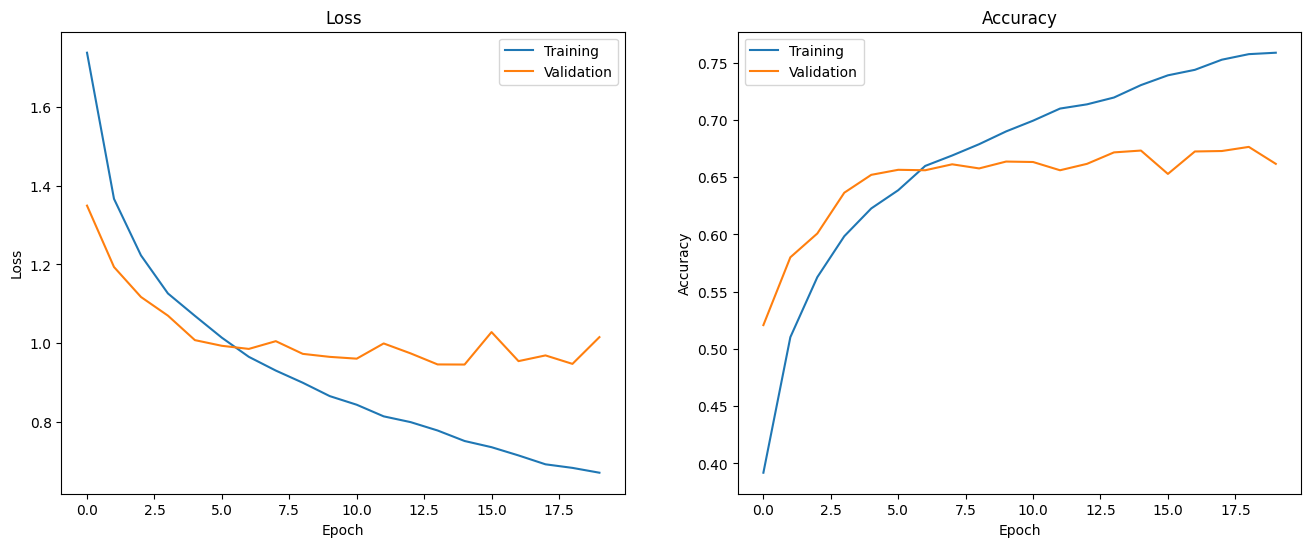

In [68]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(history_smaller.history['loss'])
plt.plot(history_smaller.history['val_loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Training', 'Validation'])
plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot(history_smaller.history['accuracy'])
plt.plot(history_smaller.history['val_accuracy'])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Training', 'Validation'])
plt.title('Accuracy')

In [69]:
#evaluate the model on test set
##### YOUR CODE STARTS #####
smaller_model.evaluate(X_test_norm, y_test)
##### YOUR CODE ENDS #####

313/313 [==============================] - 4s 13ms/step - loss: 1.0142 - accuracy: 0.6611


[1.0142344236373901, 0.6610999703407288]

<font color='red'> **(b)** Now modify the initial CNN model so that the total number of parameters is exactly 1480742. As in the previous subtask, you can change any architectural aspects of the model. Take your time to study how changes in different parameters impact the number of overall weights. Here, you only have to change **one type** of parameters to gain the required total number of weights. Finally, train the model, visualise the learning curves and evaluate it on the test set (**1.5 points**). </font>

In [3]:
##### YOUR CODE STARTS #####
x = Input(shape=(32, 32, 3))
c1 = Conv2D(64, (3, 3), strides=(1, 1), padding="same")(x)
b1 = BatchNormalization()(c1)
a1 = Activation('relu')(b1)
c2 = Conv2D(64, (3, 3), strides=(1, 1), padding="valid")(a1)
b2 = BatchNormalization()(c2)
a2 = Activation('relu')(b2)
p2 = MaxPooling2D(pool_size=2)(a2)
d2 = Dropout(rate=0.25)(p2)
f2 = Flatten()(d2) # tensor into vector
h3 = Dense(100)(f2)
b3 = BatchNormalization()(h3)
a3 = Activation('relu')(b3)
d3 = Dropout(rate=0.5)(a3)
z = Dense(10)(d3)
p = Activation('softmax')(z)
##### YOUR CODE ENDS #####

In [4]:
bigger_model = Model(inputs=x, outputs=p)
bigger_model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(lr=0.001), metrics=['accuracy'])
bigger_model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d (Conv2D)             (None, 32, 32, 64)        1792      
                                                                 
 batch_normalization (Batch  (None, 32, 32, 64)        256       
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 32, 32, 64)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 30, 30, 64)        36928     
                                                                 
 batch_normalization_1 (Bat  (None, 30, 30, 64)        256       
 chNormalization)                                            

In [5]:
# Fit the model; returns History object
history_bigger = bigger_model.fit(X_train_norm, y_train, batch_size=64, epochs=20, validation_split=0.1)

Epoch 1/20
352/352 [==============================] - 19s 16ms/step - loss: 1.6140 - accuracy: 0.4371 - val_loss: 1.4862 - val_accuracy: 0.4884
Epoch 2/20
352/352 [==============================] - 5s 14ms/step - loss: 1.2053 - accuracy: 0.5752 - val_loss: 1.0489 - val_accuracy: 0.6264
Epoch 3/20
352/352 [==============================] - 5s 15ms/step - loss: 1.0542 - accuracy: 0.6311 - val_loss: 1.0162 - val_accuracy: 0.6452
Epoch 4/20
352/352 [==============================] - 5s 14ms/step - loss: 0.9515 - accuracy: 0.6643 - val_loss: 1.0068 - val_accuracy: 0.6556
Epoch 5/20
352/352 [==============================] - 5s 13ms/step - loss: 0.8717 - accuracy: 0.6954 - val_loss: 0.9403 - val_accuracy: 0.6760
Epoch 6/20
352/352 [==============================] - 5s 14ms/step - loss: 0.8029 - accuracy: 0.7180 - val_loss: 0.9452 - val_accuracy: 0.6732
Epoch 7/20
352/352 [==============================] - 5s 13ms/step - loss: 0.7329 - accuracy: 0.7403 - val_loss: 0.9538 - val_accuracy: 0.666

Text(0.5, 1.0, 'Accuracy')

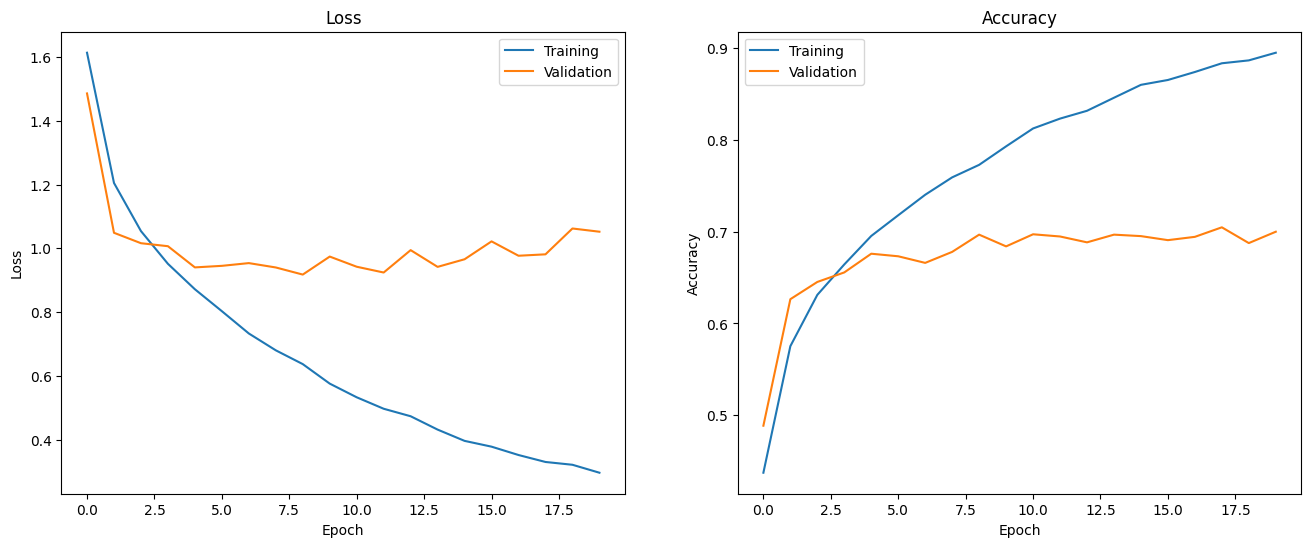

In [8]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.plot(history_bigger.history['loss'])
plt.plot(history_bigger.history['val_loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Training', 'Validation'])
plt.title('Loss')

plt.subplot(1, 2, 2)
plt.plot(history_bigger.history['accuracy'])
plt.plot(history_bigger.history['val_accuracy'])
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Training', 'Validation'])
plt.title('Accuracy')

In [9]:
#evaluate the model on test set
##### YOUR CODE STARTS #####
bigger_model.evaluate(X_test_norm, y_test)
##### YOUR CODE ENDS #####

313/313 [==============================] - 2s 5ms/step - loss: 1.0962 - accuracy: 0.6842


[1.0962169170379639, 0.6841999888420105]

<font color='red'> **(c)** Compare learning curves for smaller and bigger versions and say which version has overfitted the data? Why do you think so? Which network you would run in production? (**1 point**). </font>

<font color='red'>  Answer to **(c)**: </font>

Bigger model is overfitted because difference in accuracy between training and validation is ~21%. For smaller model this difference is twice smaller ~10%

## Homework exercise 3 (2 points): Create your own dataset and build a CNN model using fast.ai API
<font color='red'> In this exercise, you have a chance to test if CNN can distinguish between images of your favourite objects. </font>

In [1]:
!pip install fastai==1.0.61

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.2/239.2 kB 5.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.0/354.0 kB 22.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for nvidia-ml-py3: filename=nvidia_ml_py3-7.352.0-py3-none-any.whl size=19171 sha256=ed6725c852155d29a48c8f8346b73d06a9104dcc11e4e914b6ed07ea1e511e47
  Stored in directory: /root/.cache/pip/wheels/5c/d8/c0/46899f8be7a75a2ffd197a23c8797700ea858b9b34819fbf9e
Successfully built nvidia-ml-py3
  Attempting uninstall: fastai
    Found existing installation: fastai 2.7.13
    Uninstalling fastai-2.7.13:
      Successfully uninstalled fastai-2.7.13


In [2]:
# Some setup first as usual
from fastai.vision import *
from fastai.metrics import error_rate

# We don't like warnings
import warnings
warnings.filterwarnings('ignore')

from urllib.request import urlopen

<font color='red'> **(a)** Create your own dataset with two or more classes using the same approach we used in the class. But this time choose classes yourself. **(1 point)** </font>

In [3]:
##### YOUR CODE STARTS #####
from google.colab import files
uploaded = files.upload()
##### YOUR CODE ENDS #####

Saving wolf.csv to wolf.csv


In [4]:
!ls

sample_data  wolf.csv


In [5]:
##### YOUR CODE STARTS #####
from google.colab import files
uploaded = files.upload()
##### YOUR CODE ENDS #####

Saving haski.csv to haski.csv


In [6]:
!ls

haski.csv  sample_data	wolf.csv


In [7]:
folder = 'haski'
file = 'haski.csv'

In [8]:
path = Path('data/dogs')
dest = path/folder
dest.mkdir(parents=True, exist_ok=True)

In [9]:
folder = 'wolf'
file = 'wolf.csv'

In [10]:
path = Path('data/dogs')
dest = path/folder
dest.mkdir(parents=True, exist_ok=True)

In [11]:
path.ls()

[PosixPath('data/dogs/haski'), PosixPath('data/dogs/wolf')]

In [12]:
folder = 'haski'
dest = path/folder
download_images('haski.csv', dest, max_pics=400)

In [13]:
folder = 'wolf'
dest = path/folder
download_images('wolf.csv', dest, max_pics=400)

In [14]:
classes = ['haski','wolf']

In [19]:
for c in classes:
    print(c)
    verify_images(path/c, delete=True, max_size=500)

haski
wolf


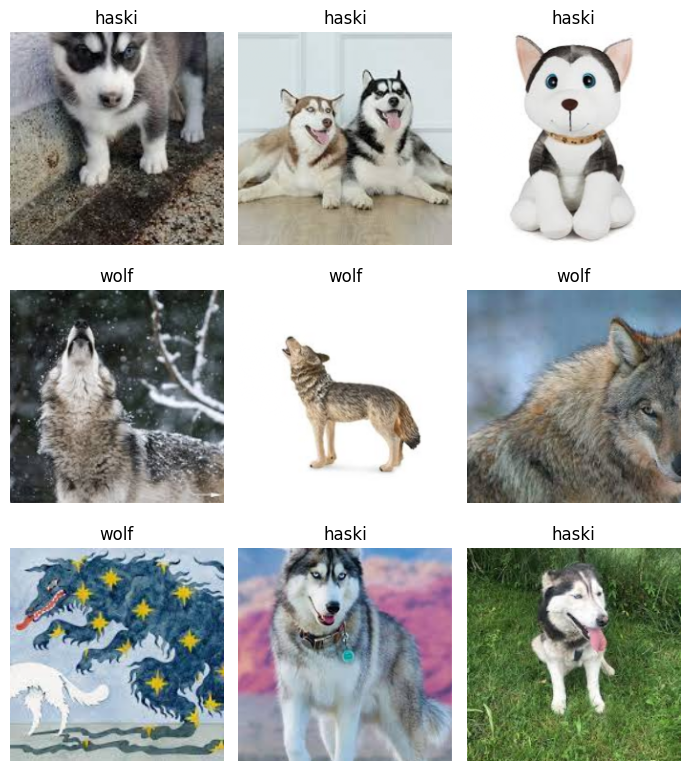

In [15]:
np.random.seed(42)
data = ImageDataBunch.from_folder(path, train=".", valid_pct=0.2,
                                  size=224, num_workers=4).normalize(imagenet_stats)

data.show_batch(rows=3, figsize=(7,8))

In [ ]:
# add more cells as necessary

<font color='red'> **(b)** train a neural network on images you have acquired **(0.5 points)** </font>

In [16]:
##### YOUR CODE STARTS #####
learn = cnn_learner(data, models.resnet34, metrics=accuracy)
learn.fit_one_cycle(5)
##### YOUR CODE ENDS #####

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth
100%|██████████| 83.3M/83.3M [00:02<00:00, 34.1MB/s]


epoch,train_loss,valid_loss,accuracy,time
0,0.947766,0.244405,0.931035,00:13
1,0.559239,0.236652,0.942529,00:03
2,0.366961,0.150429,0.977012,00:03
3,0.271696,0.125304,0.965517,00:03
4,0.213415,0.115039,0.977012,00:04


Plot the confusion matrix to make sure that you model has learned something:

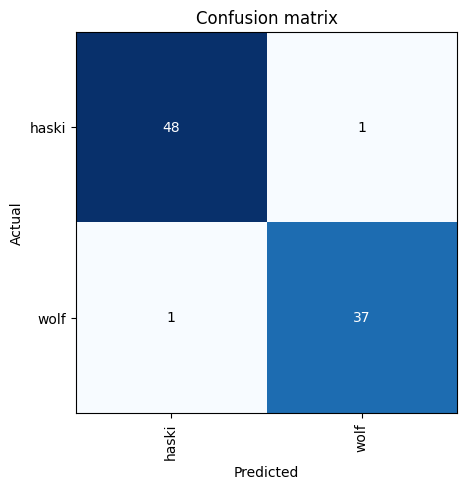

In [17]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

<font color='red'> **(c)** Test your model on one or more images from the internet that represent classes you have chosen, but unlikely to be in the training data (you can change your search query). Print out class probabilities for one of these test images. **(0.5 points)** </font>

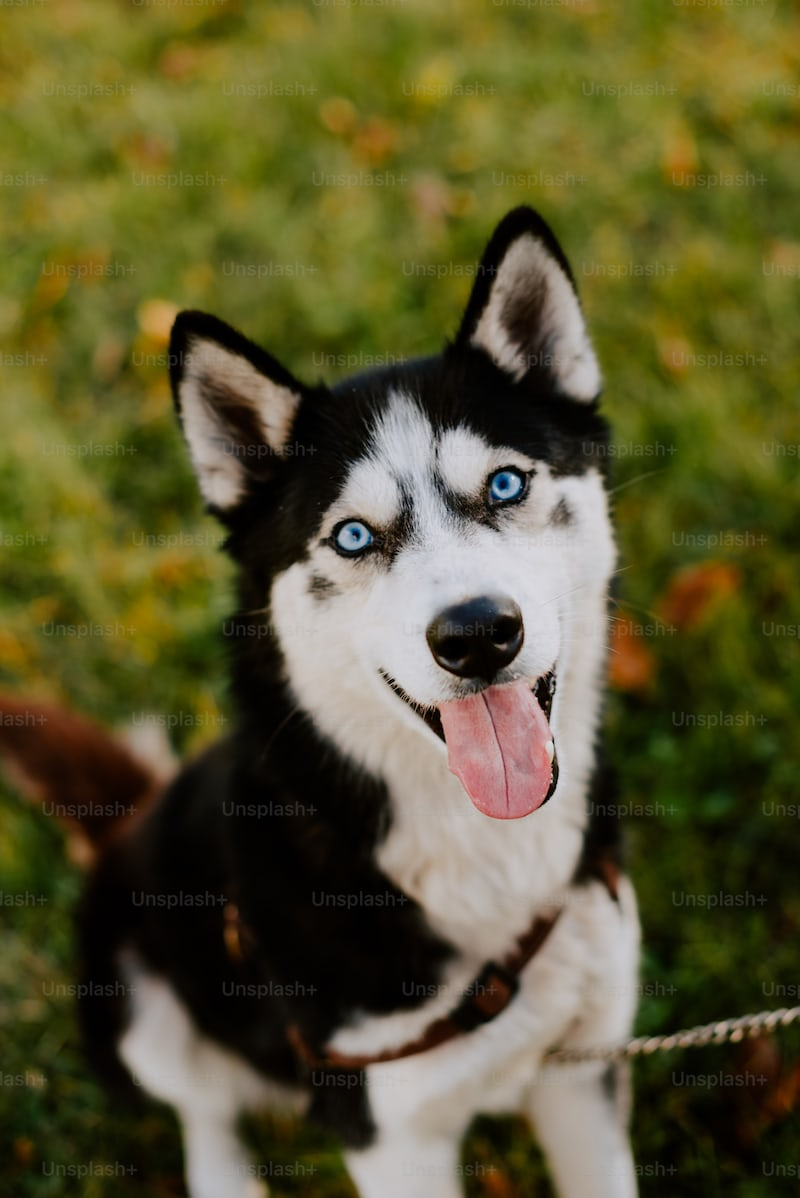

In [23]:
##### YOUR CODE STARTS #####

img = open_image(urlopen('https://plus.unsplash.com/premium_photo-1667729435876-3a83af97f536?auto=format&fit=crop&q=60&w=800&ixlib=rb-4.0.3&ixid=M3wxMjA3fDB8MHxzZWFyY2h8MXx8aHVza3l8ZW58MHx8MHx8fDA%3D'))

img
##### YOUR CODE ENDS #####

In [40]:
# What are the probabilities of different classes for this image?
##### YOUR CODE STARTS #####
pred_class,pred_idx,outputs = learn.predict(img)
print(pred_class.obj)
print(f"haski=${outputs[pred_idx]} wolf={outputs[1]:.1f}")
##### YOUR CODE ENDS #####

haski
haski=$1.0 wolf=0.0


# Bonus exercises
*(NB, these are optional exercises!)*

## Bonus exercise 1 (2 bonus points):

<font color='red'> [Stable Diffusion](https://stability.ai/blog/stable-diffusion-announcement) model has been recently shown to produce trully impressive results in image generation. Let's explore some of its power in this auxiliarly exercise. Use Stable Diffusion model from this [colab](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/stable_diffusion.ipynb?hl=en). Generate several tricky images to test the model you trained in the exercise 3. Report the images that you have generated with Stable Diffusion, prompt that you have used for generating them, the number of iterations that you used to generate images and the classification results from your CNN model. Shortly summarise the results you have obtained. </font>

## Bonus exercise 2 (2 bonus points):

<font color='red'> Modify the 3-layer neural network code from homework exercise 1 by replacing tanh activation functions with sigmoid. Adjust both the forward and backward propagation paths accordingly to accommodate this change.
Afterward, execute the code for the same number of iterations (epochs) as in exercise 1 and compute accuracy. Visualize the obtained classifier and interpret the results.
Did the network with sigmoid perform better or worse?
If the performance with sigmoid activations is worse than with tanh, identify the possible reasons and explain potential solutions. Implement the necessary fixes and rerun the updated code while keeping the original architecture of the neural network (three layers with hidden layers using sigmoid activation function). Your objective is to achieve the same performance as with tanh (0.99). </font>

# Comments (optional feedback to the course instructors)
Here, please, leave your comments regarding the homework, possibly answering the following questions:
* how much time did you spend on this homework?
* was it too hard/easy for you?
* what would you suggest to add or remove?
* anything else you would like to tell us

Your comments:

* HW3 was really challenging. Total time spent to submit the HW3: 11:51:21
* HW3 was hard
* Please add more asserts into the code or comments E.g. 'You should expect accuracy 99%' etc

# <font color='red'>  End of the homework. Please don't delete this cell.</font>